# Install & imports

In [1]:
!pip install -q torch-geometric ipywidgets

import torch
import torch.nn as nn
import torch.nn.functional as torch_F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
from pathlib import Path
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cuda


# Reconnect paths, load data

In [2]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/PD_EEG_Thesis_Features_v2')
FEAT_DIR      = PROJECT_ROOT / 'data' / 'features'
SEG_DIR       = PROJECT_ROOT / 'data' / 'segments'
REGION_DIR    = PROJECT_ROOT / 'data' / 'regional_features'
RESULTS_DIR   = PROJECT_ROOT / 'results'
RESULTS_REGIONAL_DIR = PROJECT_ROOT / 'results_regional'

# All-channel data (existing)
d_feat = np.load(str(FEAT_DIR / 'features_all.npz'))
node_features_all, y_all, subjects_all = d_feat['node_features'], d_feat['y'], d_feat['subjects']

d_seg = np.load(str(SEG_DIR / 'segments_all.npz'))
X_raw_all, subjects_raw_all = d_seg['X'], d_seg['subjects']

FEATURE_NAMES = ['hjorth_complexity', 'zero_crossing_rate', 'hjorth_mobility', 'line_length',
                 'kurtosis', 'peak_to_peak', 'beta_power', 'theta_beta_ratio', 'theta_power',
                 'spectral_entropy', 'alpha_beta_ratio', 'spectral_centroid', 'spectral_edge_95',
                 'gamma_power', 'stft_low_band_power', 'wavelet_entropy', 'teager_energy']

manifest = pd.read_csv(PROJECT_ROOT / 'manifest.csv')
subject_to_group = {}
unique_subjects = np.unique(subjects_all)
for s in unique_subjects:
    lbl = y_all[subjects_all == s][0]
    subject_to_group[s] = 'PD' if lbl == 1 else 'Control'

print(f'Loaded All-channel data: {len(unique_subjects)} subjects, {node_features_all.shape[0]} windows')

# Regional data — node_features/adjacency are PRECOMPUTED per region and index-aligned
# with X_raw_all / subjects_all, so no recomputation needed at inference time.
REGION_NAMES = ['Left_Frontal', 'Right_Frontal', 'Left_Parietal', 'Right_Parietal']
regional_data = {}
for region in REGION_NAMES:
    d = np.load(str(REGION_DIR / f'features_{region}.npz'), allow_pickle=True)
    regional_data[region] = {
        'node_features': d['node_features'], 'adjacency': d['adjacency'],
        'channel_names': list(d['channel_names']),
    }
    print(f'Loaded {region}: {d["node_features"].shape[2]} channels, {d["node_features"].shape[0]} windows')

CONFIG_NAMES = ['All'] + REGION_NAMES
MODEL_NAMES = ['TGCN', 'TGIN', 'TGAT']

Mounted at /content/drive
Loaded All-channel data: 149 subjects, 3915 windows
Loaded Left_Frontal: 10 channels, 3915 windows
Loaded Right_Frontal: 10 channels, 3915 windows
Loaded Left_Parietal: 8 channels, 3915 windows
Loaded Right_Parietal: 8 channels, 3915 windows


# Recover channel names

In [3]:
!pip install -q mne
import mne

print('Recovering channel names for visualization...')
common_chs = None
for _, row in manifest.iterrows():
    raw_check = mne.io.read_raw_edf(row['edf_path'], preload=False, verbose=False)
    chs = set(raw_check.ch_names)
    common_chs = chs if common_chs is None else common_chs & chs

ref_raw = mne.io.read_raw_edf(manifest.iloc[0]['edf_path'], preload=False, verbose=False)
CHANNEL_NAMES = [ch for ch in ref_raw.ch_names if ch in common_chs]
print(f'Recovered {len(CHANNEL_NAMES)} channel names')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 60.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
Recovering channel names for visualization...
Recovered 60 channel names


# Cell 3b

In [4]:
CORR_THRESHOLD = 0.3

def compute_adjacency(window):
    corr = np.nan_to_num(np.corrcoef(window), nan=0.0)
    adj  = np.where(corr >= CORR_THRESHOLD, corr, 0.0).astype(np.float32)
    np.fill_diagonal(adj, 0.0)
    return adj

def get_config_channels(config):
    return CHANNEL_NAMES if config == 'All' else regional_data[config]['channel_names']

def get_region_channel_indices(config):
    """Indices into the ORIGINAL 60-channel order, for slicing raw EEG per config."""
    if config == 'All':
        return list(range(len(CHANNEL_NAMES)))
    region_chs = regional_data[config]['channel_names']
    return [CHANNEL_NAMES.index(ch) for ch in region_chs]

print('Config/channel helper functions ready.')

Config/channel helper functions ready.


# Model definitions

In [5]:
N_TIMESTEPS, N_FEATURES = 6, 17
HIDDEN_DIM, N_HEADS, DROPOUT = 48, 4, 0.25
CORR_THRESHOLD = 0.3

def compute_adjacency(window):
    corr = np.nan_to_num(np.corrcoef(window), nan=0.0)
    adj  = np.where(corr >= CORR_THRESHOLD, corr, 0.0).astype(np.float32)
    np.fill_diagonal(adj, 0.0)
    return adj

class AttentionPool(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, 1)
    def forward(self, emb):
        weights = torch_F.softmax(self.attn(emb), dim=1)
        return (weights * emb).sum(dim=1), weights.squeeze(-1)

class TGCN(nn.Module):
    def __init__(self, n_features, hidden_dim, dropout):
        super().__init__()
        self.gc_weight  = nn.Linear(n_features, hidden_dim, bias=False)
        self.pool       = AttentionPool(hidden_dim)
        self.gru        = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=2, dropout=dropout)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 2)
    def graph_conv(self, x, adj):
        deg = adj.sum(dim=-1, keepdim=True).clamp(min=1)
        x   = torch.bmm(adj / deg, x)
        return torch_F.relu(self.gc_weight(x))
    def forward(self, node_feat, adj, return_attn=False):
        B, T, N, Fdim = node_feat.shape
        embs, attns = [], []
        for t in range(T):
            h = self.graph_conv(node_feat[:, t], adj)
            pooled, w = self.pool(h)
            embs.append(pooled); attns.append(w)
        seq, _ = self.gru(torch.stack(embs, dim=1))
        out = self.classifier(self.dropout(seq[:, -1, :]))
        if return_attn:
            return out, torch.stack(attns, dim=1)
        return out

class TGIN(nn.Module):
    def __init__(self, n_features, hidden_dim, dropout):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(n_features, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, hidden_dim))
        self.eps  = nn.Parameter(torch.zeros(1))
        self.pool = AttentionPool(hidden_dim)
        self.gru  = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=2, dropout=dropout)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 2)
    def graph_gin(self, x, adj):
        agg = torch.bmm(adj, x)
        return self.mlp((1 + self.eps) * x + agg)
    def forward(self, node_feat, adj, return_attn=False):
        B, T, N, Fdim = node_feat.shape
        embs, attns = [], []
        for t in range(T):
            h = self.graph_gin(node_feat[:, t], adj)
            pooled, w = self.pool(h)
            embs.append(pooled); attns.append(w)
        seq, _ = self.gru(torch.stack(embs, dim=1))
        out = self.classifier(self.dropout(seq[:, -1, :]))
        if return_attn:
            return out, torch.stack(attns, dim=1)
        return out

class TGAT(nn.Module):
    def __init__(self, n_features, hidden_dim, n_heads, dropout):
        super().__init__()
        self.n_heads, self.head_dim = n_heads, hidden_dim // n_heads
        self.W_q = nn.Linear(n_features, hidden_dim, bias=False)
        self.W_k = nn.Linear(n_features, hidden_dim, bias=False)
        self.W_v = nn.Linear(n_features, hidden_dim, bias=False)
        self.W_o = nn.Linear(hidden_dim, hidden_dim)
        self.gru        = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=2, dropout=dropout)
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 2)
    def graph_attention(self, x, adj):
        B, N, Fdim = x.shape
        H, D = self.n_heads, self.head_dim
        Q = self.W_q(x).view(B, N, H, D).transpose(1, 2)
        K = self.W_k(x).view(B, N, H, D).transpose(1, 2)
        V = self.W_v(x).view(B, N, H, D).transpose(1, 2)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (D ** 0.5)
        mask   = (adj == 0).unsqueeze(1).expand_as(scores)
        scores = scores.masked_fill(mask, float('-inf'))
        scores = torch.nan_to_num(scores, nan=0.0, neginf=-1e9)
        attn   = torch_F.softmax(scores, dim=-1)
        out    = torch.matmul(attn, V).transpose(1, 2).contiguous().view(B, N, -1)
        return torch_F.relu(self.W_o(out))
    def forward(self, node_feat, adj, return_attn=False):
        B, T, N, Fdim = node_feat.shape
        embs = [self.graph_attention(node_feat[:, t], adj).mean(dim=1) for t in range(T)]
        seq, _ = self.gru(torch.stack(embs, dim=1))
        out = self.classifier(self.dropout(seq[:, -1, :]))
        if return_attn:
            return out, None
        return out

def build_model(name):
    if name == 'TGCN': return TGCN(N_FEATURES, HIDDEN_DIM, DROPOUT).to(DEVICE)
    if name == 'TGIN': return TGIN(N_FEATURES, HIDDEN_DIM, DROPOUT).to(DEVICE)
    if name == 'TGAT': return TGAT(N_FEATURES, HIDDEN_DIM, N_HEADS, DROPOUT).to(DEVICE)

print('Model definitions ready.')

Model definitions ready.


# Inference helper

In [6]:
loaded_models_cache = {}   # (model_name, config) -> model, populated lazily on first use

def get_model(model_name, config):
    key = (model_name, config)
    if key in loaded_models_cache:
        return loaded_models_cache[key]

    model = build_model(model_name)
    if config == 'All':
        ckpt_path = RESULTS_DIR / f'{model_name}_trained.pt'
    else:
        ckpt_path = RESULTS_REGIONAL_DIR / f'{model_name}_{config}.pt'

    state = torch.load(str(ckpt_path), map_location=DEVICE)
    model.load_state_dict(state)
    model.eval()
    loaded_models_cache[key] = model
    return model


def get_windows_for_subject(subject_id):
    mask = subjects_all == subject_id
    return np.where(mask)[0]


def get_window_options(subject_id):
    n = len(get_windows_for_subject(subject_id))
    WINDOW_LENGTH_SEC = 6.0
    return [
        (f'Segment {i} ({i * WINDOW_LENGTH_SEC:.1f}s – {(i + 1) * WINDOW_LENGTH_SEC:.1f}s)', i)
        for i in range(n)
    ]


def run_inference(subject_id, local_window_idx, model_name, config):
    global_indices = get_windows_for_subject(subject_id)
    global_idx = global_indices[local_window_idx]

    if config == 'All':
        nf = node_features_all[global_idx]
        raw_window_full = X_raw_all[np.where(subjects_raw_all == subject_id)[0][local_window_idx]]
        adj = compute_adjacency(raw_window_full)
        raw_window_for_plot = raw_window_full
    else:
        nf = regional_data[config]['node_features'][global_idx]
        adj = regional_data[config]['adjacency'][global_idx]
        raw_window_full = X_raw_all[np.where(subjects_raw_all == subject_id)[0][local_window_idx]]
        ch_idx = get_region_channel_indices(config)
        raw_window_for_plot = raw_window_full[ch_idx]

    nf_t  = torch.tensor(nf, dtype=torch.float32).unsqueeze(0).to(DEVICE)
    adj_t = torch.tensor(adj, dtype=torch.float32).unsqueeze(0).to(DEVICE)

    model = get_model(model_name, config)
    with torch.no_grad():
        if model_name in ['TGCN', 'TGIN']:
            logits, attn = model(nf_t, adj_t, return_attn=True)
            attn_avg = attn.mean(dim=1).squeeze(0).cpu().numpy()
        else:
            logits = model(nf_t, adj_t)
            attn_avg = None

    probs = torch_F.softmax(logits, dim=1).squeeze(0).cpu().numpy()
    pred  = int(np.argmax(probs))
    true_label = int(y_all[global_idx])

    return {
        'pred': pred, 'pred_label': 'PD' if pred == 1 else 'Control',
        'confidence': probs[pred], 'prob_pd': probs[1], 'prob_control': probs[0],
        'true_label': true_label, 'true_label_name': 'PD' if true_label == 1 else 'Control',
        'correct': pred == true_label,
        'feature_values': nf.mean(axis=0).mean(axis=0),
        'attn_weights': attn_avg,
        'raw_window': raw_window_for_plot,
    }

print('Region-aware inference helper ready (lazy model loading with cache).')

Region-aware inference helper ready (lazy model loading with cache).


# Widget interface

In [10]:
subject_options = [(f'sub-{s} ({subject_to_group[s]})', s) for s in unique_subjects]

subject_dd = widgets.Dropdown(options=subject_options, description='Subject:', style={'description_width':'110px'})
window_dd  = widgets.Dropdown(options=get_window_options(subject_options[0][1]),
                              description='Segment:', style={'description_width':'110px'})
config_dd  = widgets.Dropdown(options=CONFIG_NAMES, value='All', description='Region:', style={'description_width':'110px'})
model_dd   = widgets.Dropdown(options=MODEL_NAMES, value='TGAT', description='Model:', style={'description_width':'110px'})
view_dd    = widgets.Dropdown(
    options=['Combined EEG (region channels)', 'Channel Heatmap', 'Individual Channel'],
    description='EEG view:', style={'description_width':'110px'})
channel_dd = widgets.Dropdown(options=CHANNEL_NAMES, description='Channel:', style={'description_width':'110px'})
uv_toggle  = widgets.Checkbox(value=True, description='Display in µV (raw is in Volts)')
render_btn = widgets.Button(description='Run Inference', button_style='primary', icon='play')
reset_btn  = widgets.Button(description='Reset', button_style='warning', icon='undo')
output = widgets.Output()

REGION_COLORS = {'Left_Frontal': '#e74c3c', 'Right_Frontal': '#e67e22',
                 'Left_Parietal': '#27ae60', 'Right_Parietal': '#8e44ad', 'All': '#3498db'}

def update_windows(*args):
    window_dd.options = get_window_options(subject_dd.value)
subject_dd.observe(update_windows, names='value')

def update_channel_dd(*args):
    channel_dd.options = get_config_channels(config_dd.value)
config_dd.observe(update_channel_dd, names='value')
update_channel_dd()

DEFAULTS = {'subject': subject_options[0][1], 'window': 0, 'config': 'All', 'model': 'TGAT',
           'view': 'Combined EEG (region channels)', 'uv': True}


def plot_combined(raw_uV, ch_names, sfreq, title, color):
    n_ch = len(ch_names)
    t = np.arange(raw_uV.shape[1]) / sfreq
    spacing = np.median(np.std(raw_uV, axis=1)) * 5

    fig, ax = plt.subplots(figsize=(14, max(5, n_ch*0.4)))
    for i, ch in enumerate(ch_names):
        offset = (n_ch - 1 - i) * spacing
        ax.plot(t, raw_uV[i] + offset, linewidth=0.6, color=color)
    ax.set_yticks([(n_ch-1-i)*spacing for i in range(n_ch)])
    ax.set_yticklabels(ch_names, fontsize=8)
    ax.set_xlabel('Time (s)')
    ax.set_title(title, fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()


def plot_heatmap(raw_uV, ch_names, sfreq, title):
    n_ch = len(ch_names)
    t_max = raw_uV.shape[1] / sfreq
    vmax = np.percentile(np.abs(raw_uV), 98)
    fig, ax = plt.subplots(figsize=(13, max(4, n_ch*0.3)))
    im = ax.imshow(raw_uV, aspect='auto', cmap='RdBu_r', vmin=-vmax, vmax=vmax, extent=[0, t_max, n_ch, 0])
    ax.set_yticks(np.arange(n_ch)+0.5); ax.set_yticklabels(ch_names, fontsize=8)
    ax.set_xlabel('Time (s)'); ax.set_title(title, fontsize=12, fontweight='bold')
    plt.colorbar(im, ax=ax, label='Amplitude (µV)', shrink=0.6)
    plt.tight_layout()
    plt.show()


def plot_single_channel(raw_uV, ch_names, channel_name, sfreq, title, color):
    if channel_name not in ch_names:
        print(f'⚠️ "{channel_name}" is not part of the selected region\'s channels '
              f'({", ".join(ch_names)}). Pick a channel belonging to this region.')
        return
    idx = ch_names.index(channel_name)
    d = raw_uV[idx]
    t = np.arange(len(d)) / sfreq
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(t, d, linewidth=0.9, color=color)
    ax.set_xlabel('Time (s)'); ax.set_ylabel('Amplitude (µV)')
    ax.set_title(f'{title}\nChannel: {channel_name}', fontsize=12, fontweight='bold')
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def on_render(b):
    with output:
        clear_output(wait=True)
        config = config_dd.value
        result = run_inference(subject_dd.value, window_dd.value, model_dd.value, config)

        status = '✓ CORRECT' if result['correct'] else '✗ INCORRECT'
        seg_label = [lbl for lbl, val in window_dd.options if val == window_dd.value][0]
        print(f'Subject: sub-{subject_dd.value}  |  Region: {config}  |  Model: {model_dd.value}  |  {seg_label}')
        print(f'True label: {result["true_label_name"]}   |   Predicted: {result["pred_label"]} '
              f'(confidence {result["confidence"]:.1%})   |   {status}')
        print(f'  P(Control) = {result["prob_control"]:.3f}   P(PD) = {result["prob_pd"]:.3f}\n')

        raw_uV = result['raw_window'] * (1e6 if uv_toggle.value else 1.0)
        ch_names_cfg = get_config_channels(config)
        color = REGION_COLORS[config]
        title_base = f'sub-{subject_dd.value} ({result["true_label_name"]}) — {config} — {seg_label}'

        if view_dd.value == 'Combined EEG (region channels)':
            plot_combined(raw_uV, ch_names_cfg, 500.0, title_base, color)
        elif view_dd.value == 'Channel Heatmap':
            plot_heatmap(raw_uV, ch_names_cfg, 500.0, title_base)
        elif view_dd.value == 'Individual Channel':
            plot_single_channel(raw_uV, ch_names_cfg, channel_dd.value, 500.0, title_base, color)

        n_plots = 2 if result['attn_weights'] is not None else 1
        fig, axes = plt.subplots(1, n_plots, figsize=(8*n_plots, 4.5))
        if n_plots == 1: axes = [axes]
        axes[0].barh(FEATURE_NAMES, result['feature_values'], color='#3498db')
        axes[0].set_title('Feature Values (this segment)'); axes[0].set_xlabel('Value')

        if result['attn_weights'] is not None:
            top_idx = np.argsort(result['attn_weights'])[::-1][:min(15, len(ch_names_cfg))]
            top_labels = [ch_names_cfg[i] for i in top_idx]
            axes[1].barh(top_labels, result['attn_weights'][top_idx], color='#e67e22')
            axes[1].set_title(f'{model_dd.value} — Channel Attention ({config})')
            axes[1].set_xlabel('Attention weight')
        plt.tight_layout()
        plt.show()

        if result['attn_weights'] is None:
            print('\nNote: TGAT uses internal Q/K/V attention, not pooling attention.')


def on_reset(b):
    subject_dd.value = DEFAULTS['subject']
    update_windows()
    window_dd.value = DEFAULTS['window']
    config_dd.value = DEFAULTS['config']
    update_channel_dd()
    model_dd.value = DEFAULTS['model']
    view_dd.value = DEFAULTS['view']
    uv_toggle.value = DEFAULTS['uv']
    with output:
        clear_output(wait=True)

render_btn.on_click(on_render)
reset_btn.on_click(on_reset)

ui = widgets.VBox([
    widgets.HTML('<b>Select data:</b>'),
    subject_dd, window_dd, config_dd, model_dd,
    widgets.HTML('<b>EEG signal view:</b>'),
    view_dd,
    widgets.HTML('<i>Channel selector only used when EEG view = "Individual Channel"</i>'),
    channel_dd,
    uv_toggle,
    widgets.HBox([render_btn, reset_btn]),
])
display(ui, output)

Output()

# Results summary

=== FINAL VALIDATED RESULTS — All Channels + 4 Regions ===

        region model  n_channels  accuracy  balanced_accuracy       f1      auc
           All  TGCN          60  0.730463           0.690990 0.800000 0.820087
           All  TGIN          60  0.674641           0.639568 0.753027 0.758490
           All  TGAT          60  0.732057           0.717009 0.791045 0.828080
  Left_Frontal  TGCN          10  0.708134           0.702569 0.766284 0.760706
  Left_Frontal  TGIN          10  0.644338           0.609695 0.727717 0.708599
  Left_Frontal  TGAT          10  0.696970           0.730815 0.733894 0.799269
 Right_Frontal  TGCN          10  0.701754           0.737958 0.736990 0.779068
 Right_Frontal  TGIN          10  0.700159           0.728486 0.740331 0.758079
 Right_Frontal  TGAT          10  0.633174           0.647396 0.686649 0.724426
 Left_Parietal  TGCN           8  0.773525           0.765913 0.822500 0.860249
 Left_Parietal  TGIN           8  0.763955           0.77526

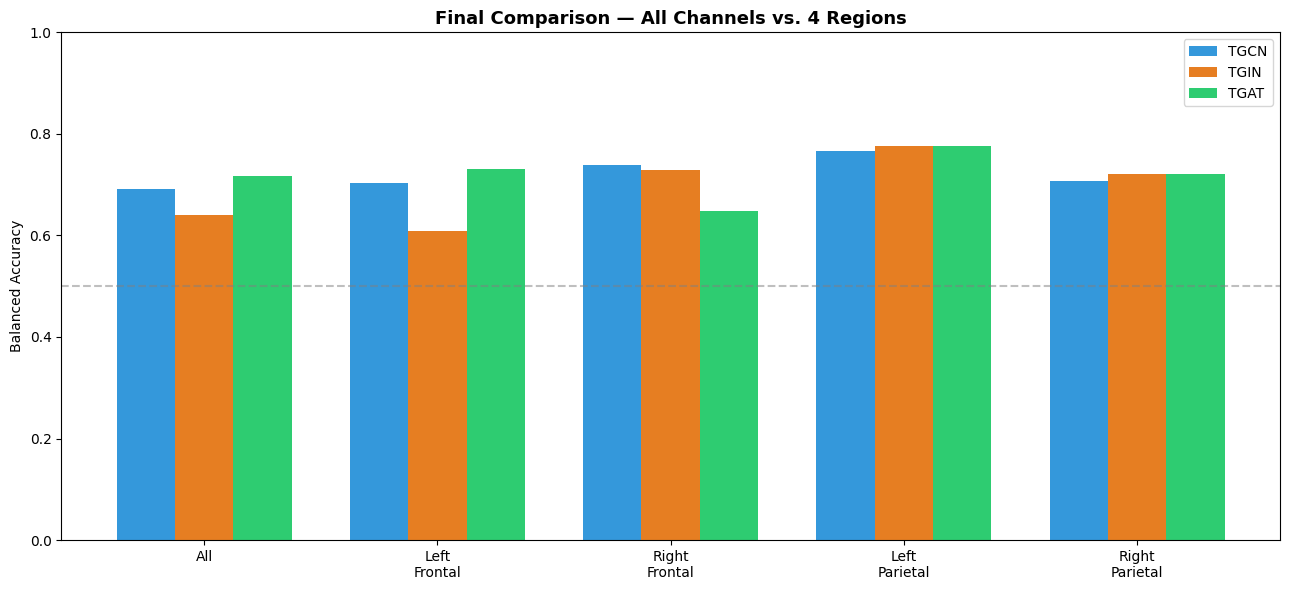

In [8]:
RESULTS_REGIONAL_PATH = PROJECT_ROOT / 'results_regional' / 'all_regions_comparison.csv'
final_comparison = pd.read_csv(RESULTS_REGIONAL_PATH)

print('=== FINAL VALIDATED RESULTS — All Channels + 4 Regions ===\n')
print(final_comparison.to_string(index=False))

best_row = final_comparison.loc[final_comparison['balanced_accuracy'].idxmax()]
print(f'\nBest overall: {best_row["region"]} / {best_row["model"]}  '
      f'(BalAcc={best_row["balanced_accuracy"]:.3f}, AUC={best_row["auc"]:.3f})')

fig, ax = plt.subplots(figsize=(13, 6))
configs_plot = ['All', 'Left_Frontal', 'Right_Frontal', 'Left_Parietal', 'Right_Parietal']
x = np.arange(len(configs_plot)); width = 0.25
colors_m = {'TGCN': '#3498db', 'TGIN': '#e67e22', 'TGAT': '#2ecc71'}

for i, m in enumerate(MODEL_NAMES):
    vals = [final_comparison[(final_comparison.region==c)&(final_comparison.model==m)]['balanced_accuracy'].values[0]
           for c in configs_plot]
    ax.bar(x + (i-1)*width, vals, width, label=m, color=colors_m[m])

ax.set_xticks(x); ax.set_xticklabels([c.replace('_','\n') for c in configs_plot])
ax.axhline(0.5, color='gray', linestyle='--', alpha=0.5)
ax.set_ylabel('Balanced Accuracy'); ax.set_ylim(0, 1); ax.legend()
ax.set_title('Final Comparison — All Channels vs. 4 Regions', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Figure 5 (Section 3.4) - Regional electrode groups. ONE self-contained Colab cell (works in any notebook session).
# Read-only: loads the saved regional feature files for the channel lists, trains nothing, writes only to figures_paper/.
# Output: Figure1_regions_3d.png / .svg / .pdf  (this is manuscript Fig. 5)

!pip install -q mne

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import mne
import warnings; warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/PD_EEG_Thesis_Features_v2')
REGION_DIR   = PROJECT_ROOT / 'data' / 'regional_features'      # read-only use: features_<region>.npz from Notebook 11
OUT_DIR      = PROJECT_ROOT / 'figures_paper'                   # same safe output folder as Notebook 13
OUT_DIR.mkdir(exist_ok=True)

mpl.rcParams.update({'font.family': ['Arial', 'Liberation Sans', 'DejaVu Sans'], 'svg.fonttype': 'none', 'pdf.fonttype': 42,
                     'axes.linewidth': 0.7})
INK, MUTED, GRID = '#1f2937', '#6b7280', '#c9ced6'

REGIONS = ['Left_Frontal', 'Right_Frontal', 'Left_Parietal', 'Right_Parietal']
REGION_LABEL = {r: r.replace('_', ' ') for r in REGIONS}
REGION_COLOR = {'Left_Frontal': '#56B4E9', 'Right_Frontal': '#0072B2', 'Left_Parietal': '#D55E00', 'Right_Parietal': '#CC79A7'}

data = {}
for r in REGIONS:
    d = np.load(str(REGION_DIR / f'features_{r}.npz'), allow_pickle=True)
    data[r] = {'nf': d['node_features'], 'adj': d['adjacency'], 'y': d['y'], 'ch': [str(c) for c in d['channel_names']]}
    print(f"{r}: {len(data[r]['ch'])} channels, node_features {data[r]['nf'].shape}, PD={int(data[r]['y'].sum())}, Control={int((data[r]['y']==0).sum())}")
assert [len(data[r]['ch']) for r in REGIONS] == [10, 10, 8, 8], 'region sizes differ from Table 3 of the paper'


# 60-channel list: reuse Notebook 13's channel_list.json if it exists, otherwise recover it from the EDF headers (same method as Notebooks 9, 11, 13)
cl = OUT_DIR / 'channel_list.json'
if cl.exists():
    CHANNEL_NAMES = json.loads(cl.read_text())['common']
else:
    manifest = pd.read_csv(PROJECT_ROOT / 'manifest.csv'); common = None
    for _, row in manifest.iterrows():
        chs = set(mne.io.read_raw_edf(row['edf_path'], preload=False, verbose=False).ch_names)
        common = chs if common is None else common & chs
    first = mne.io.read_raw_edf(manifest.iloc[0]['edf_path'], preload=False, verbose=False)
    CHANNEL_NAMES = [c for c in first.ch_names if c in common]
pos = mne.channels.make_standard_montage('standard_1020').get_positions()['ch_pos']
matched = [c for c in CHANNEL_NAMES if c in pos]
P = np.array([pos[c] for c in matched]) * 100.0                      # cm; x right, y anterior, z up
RAD = np.linalg.norm(P, axis=1).mean()
tt = np.linspace(0, 2*np.pi, 241)
def circ(plane):
    c, s = np.cos(tt) * RAD, np.sin(tt) * RAD; z0 = np.zeros_like(tt)
    return {'xy': (c, s, z0), 'xz': (c, z0, s), 'yz': (z0, c, s)}[plane]
def draw_head_lines(ax):
    for plane, lw in (('yz', 0.8), ('xz', 0.8), ('xy', 0.6)):
        x, y, z = circ(plane); ax.plot(x, y, z, color='#aab2bf', lw=lw, alpha=0.9, zorder=0)
    nx = np.array([-1.3, 0, 1.3, -1.3]); ny = np.array([RAD, RAD*1.2, RAD, RAD]); nz = np.full(4, -0.9)
    ax.plot(nx, ny, nz, color=INK, lw=1.1)
    for s in (-1, 1):
        a = np.linspace(0, 2*np.pi, 60)
        ax.plot(np.full_like(a, s*RAD*1.02), -0.4 + 1.4*np.cos(a), -0.9 + 2.6*np.sin(a), color=INK, lw=1.0)

group = {}
for r in REGIONS:
    for c in data[r]['ch']: group[c] = r
fig = plt.figure(figsize=(6.8, 5.5))
ax = fig.add_subplot(111, projection='3d', computed_zorder=False)
draw_head_lines(ax)
other = [i for i, c in enumerate(matched) if c not in group]
ax.scatter(P[other, 0], P[other, 1], P[other, 2], s=26, c='#d5d9e0', edgecolors='#9aa3b2', linewidths=0.4, depthshade=True, zorder=2)
for r in REGIONS:
    idx = [i for i, c in enumerate(matched) if group.get(c) == r]
    ax.scatter(P[idx, 0], P[idx, 1], P[idx, 2], s=78, c=REGION_COLOR[r], edgecolors='white', linewidths=0.8, depthshade=False, zorder=6)
lim = RAD * 1.08
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim * 1.2); ax.set_zlim(-lim * 0.55, lim)
ax.set_box_aspect((2 * lim, 2.2 * lim, 1.55 * lim), zoom=1.22)
ax.view_init(elev=42, azim=-58); ax.set_axis_off()
ax.text(-RAD * 1.20, -0.4, -0.9, 'L', ha='center', va='center', fontsize=9, color=MUTED, fontweight='bold')
ax.text(RAD * 1.20, -0.4, -0.9, 'R', ha='center', va='center', fontsize=9, color=MUTED, fontweight='bold')
fig.subplots_adjust(left=0.0, right=1.0, top=1.0, bottom=0.36)
# legend rows: colour dot, region name, channel list
y0 = 0.285
for k, r in enumerate(REGIONS):
    yy = y0 - k * 0.066
    fig.patches.append(mpl.patches.Circle((0.075, yy), 0.0105, transform=fig.transFigure, facecolor=REGION_COLOR[r], edgecolor='white', linewidth=0.8, figure=fig))
    fig.text(0.105, yy, f"{REGION_LABEL[r]} ({len(data[r]['ch'])})", fontsize=9, fontweight='bold', color=INK, va='center')
    fig.text(0.31, yy, ', '.join(data[r]['ch']), fontsize=8, color=MUTED, va='center')
fig.text(0.075, 0.018, 'Other channels of the 60-channel montage in grey. Standard 10-10 positions, seen from the front-left and above; L/R = left/right ear.',
         fontsize=7.2, color=MUTED, va='center')
for ext, dpi in (('png', 600), ('svg', None), ('pdf', None)):
    fig.savefig(OUT_DIR / f'Figure1_regions_3d.{ext}', dpi=dpi, bbox_inches='tight', pad_inches=0.05, facecolor='white')
plt.show()